In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt

In [3]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

cuda


In [4]:
n = 10000
x = torch.rand(n, 1) * 10
noise = torch.randn(n, 1) * (0.1 + 0.3* x)
y = (torch.sin(x)*3+noise).squeeze(1)
loader = DataLoader(TensorDataset(x, y), batch_size=128, shuffle=True)

In [5]:
class NeuralNetwork(nn.Module):
    def __init__ (self, in_dim, hid_dim, out_dim):
        super().__init__()
        self.forward_pass = nn.Sequential(
            nn.Linear(in_dim, hid_dim),
            nn.ReLU(),
            nn.Linear(hid_dim, hid_dim),
            nn.ReLU(),
            nn.Linear(hid_dim, out_dim),
        )
        
    def forward(self, x):
        return self.forward_pass(x)

In [6]:
def pinball_loss(prediction, label, quantiles):
    error = label.view(-1,1) - prediction
    return torch.max(quantiles * error, (quantiles - 1) * error).mean()
    

In [7]:
quantiles = torch.tensor([0.1, 0.5, 0.9], device=device)
in_dim = 1
hid_dim = 64
out_dim = len(quantiles)
lr = 1e-3
batch_size = 128
epochs = 500

In [8]:
model = NeuralNetwork(in_dim, hid_dim, out_dim).to(device)
optimizer = optim.Adam(model.parameters(), lr)

for epoch in range(epochs):
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        loss = pinball_loss(model(xb), yb, quantiles)
        loss.backward()
        optimizer.step()
    if epoch % 50 == 0:
        print(epoch)

0
50
100
150
200
250
300
350
400
450


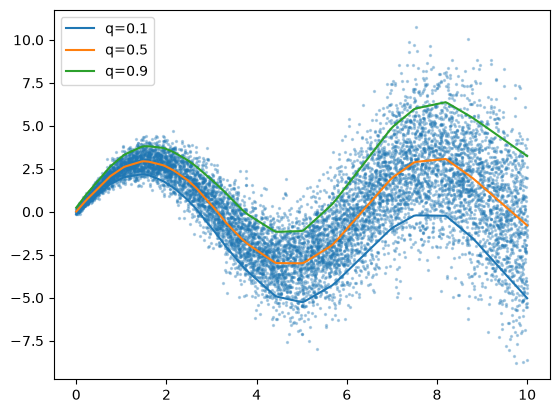

In [9]:
xs = torch.linspace(0,10,200).view(-1,1)
with torch.no_grad():
    preds = model(xs.to(device)).cpu()
    
plt.scatter(x, y, s=2, alpha=0.3)
for i, q in enumerate([0.1,0.5,0.9]):
    plt.plot(xs, preds[:,i], label = f"q={q}")
plt.legend()
plt.savefig("docs/figures/quantiles.pdf", bbox_inches = "tight")
plt.savefig("docs/figures/quantiles.png", bbox_inches = "tight")